In [117]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [118]:
df = pd.read_csv("/content/ecommerce_returns_2000.csv")

In [119]:
df.shape

(2000, 15)

In [120]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Customer_ID       2000 non-null   object 
 1   Age               1940 non-null   float64
 2   Gender            1960 non-null   object 
 3   City              1960 non-null   object 
 4   Product_Category  1960 non-null   object 
 5   Product_Price     1950 non-null   float64
 6   Quantity          2000 non-null   int64  
 7   Discount          1940 non-null   float64
 8   Payment_Method    1960 non-null   object 
 9   Order_Value       2000 non-null   float64
 10  Previous_Orders   1950 non-null   float64
 11  Customer_Rating   1920 non-null   float64
 12  Delivery_Days     1940 non-null   float64
 13  Return_Reason     1930 non-null   object 
 14  Returned          2000 non-null   int64  
dtypes: float64(7), int64(2), object(6)
memory usage: 234.5+ KB


In [121]:
df.columns

Index(['Customer_ID', 'Age', 'Gender', 'City', 'Product_Category',
       'Product_Price', 'Quantity', 'Discount', 'Payment_Method',
       'Order_Value', 'Previous_Orders', 'Customer_Rating', 'Delivery_Days',
       'Return_Reason', 'Returned'],
      dtype='object')

In [122]:
df = df.drop(['Customer_ID', 'Return_Reason'], axis=1)

#Mssing value handling

In [123]:
#checking missing values

df.isnull().sum()

,0
Age,60
Gender,40
City,40
Product_Category,40
Product_Price,50
Quantity,0
Discount,60
Payment_Method,40
Order_Value,0
Previous_Orders,50


In [124]:
#handling missing values

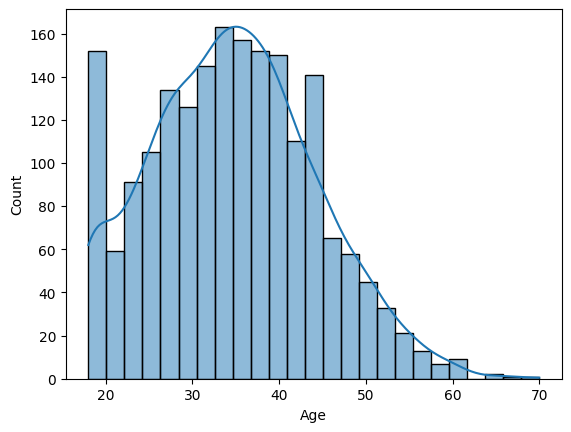

In [125]:
sns.histplot(df['Age'],kde=True)
plt.show()

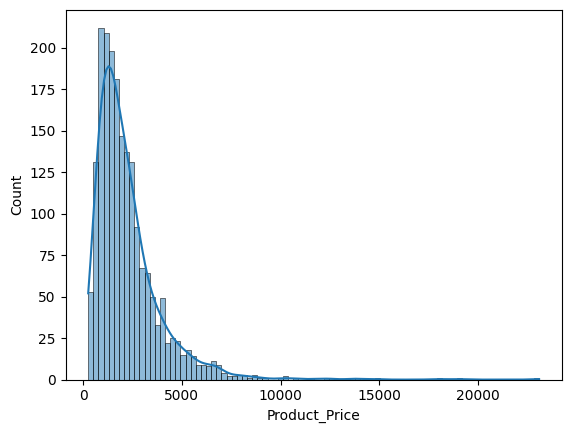

In [126]:
sns.histplot(df['Product_Price'],kde=True)
plt.show()

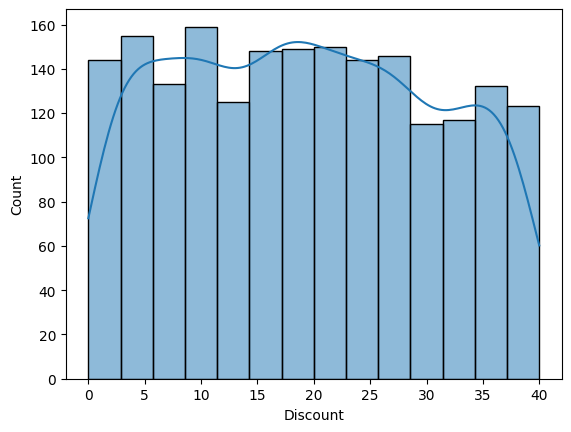

In [127]:
sns.histplot(df['Discount'],kde=True)
plt.show()

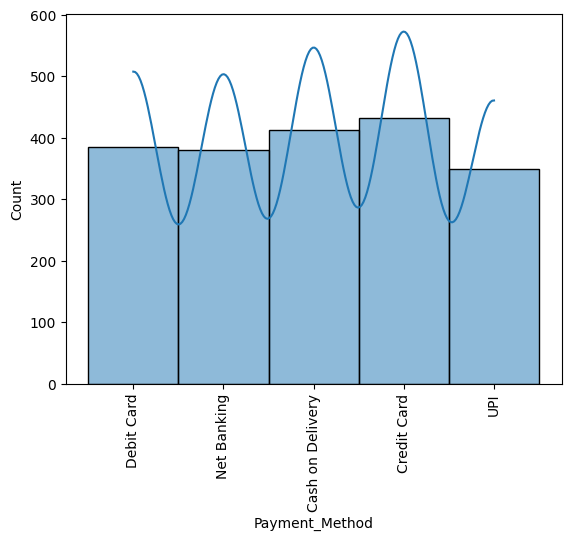

In [128]:
sns.histplot(df['Payment_Method'],kde=True)
plt.xticks(rotation=90)
plt.show()

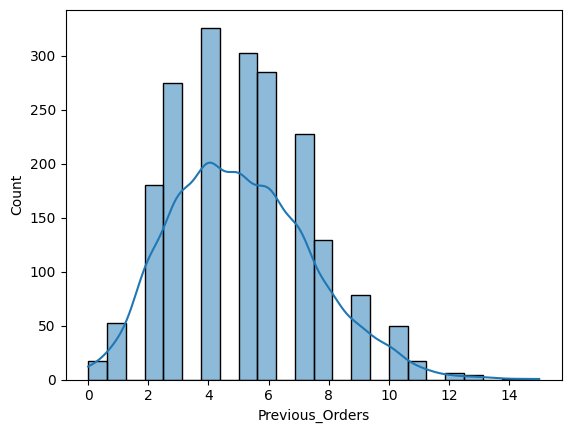

In [129]:
sns.histplot(df['Previous_Orders'],kde=True)
plt.show()

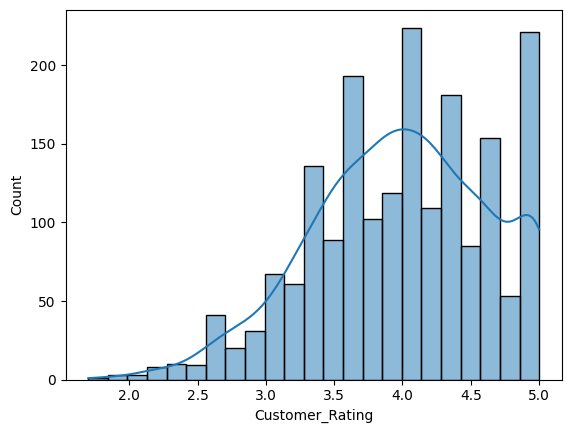

In [130]:
sns.histplot(df['Customer_Rating'],kde=True)
plt.show()

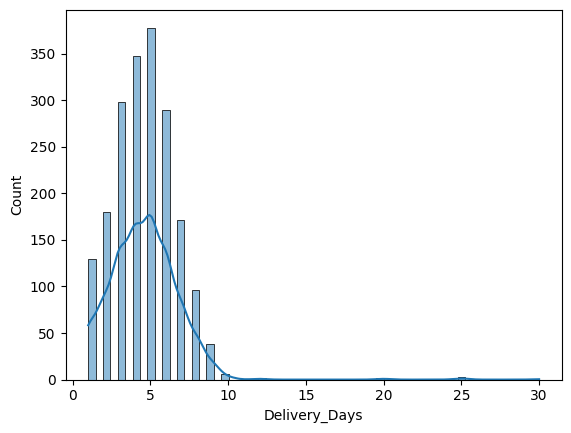

In [131]:
sns.histplot(df['Delivery_Days'],kde=True)
plt.show()

In [132]:
# Missing values handling

df["Age"] = df["Age"].fillna(df["Age"].mean())

df["City"] =df["City"].fillna(df["City"].mode()[0])

df["Gender"] = df["Gender"].ffill()

df["Product_Category"] =df["Product_Category"].fillna(df["Product_Category"].mode()[0])

df["Product_Price"] =df["Product_Price"].fillna(df["Product_Price"].median())

df["Discount"] =df["Discount"].fillna(df["Discount"].median())

df["Payment_Method"] =df["Payment_Method"].fillna(df["Payment_Method"].mode()[0])

df["Previous_Orders"] = df["Previous_Orders"].fillna(df["Previous_Orders"].median())

df['Customer_Rating'] = df["Customer_Rating"].fillna(df["Customer_Rating"].mean())

df["Delivery_Days"] = df["Delivery_Days"].fillna(df["Delivery_Days"].median())

In [133]:
df.isna().sum()

,0
Age,0
Gender,0
City,0
Product_Category,0
Product_Price,0
Quantity,0
Discount,0
Payment_Method,0
Order_Value,0
Previous_Orders,0


#Checking outliers

In [134]:
df.select_dtypes(include=['float64', 'int64']).columns

Index(['Age', 'Product_Price', 'Quantity', 'Discount', 'Order_Value',
       'Previous_Orders', 'Customer_Rating', 'Delivery_Days', 'Returned'],
      dtype='object')

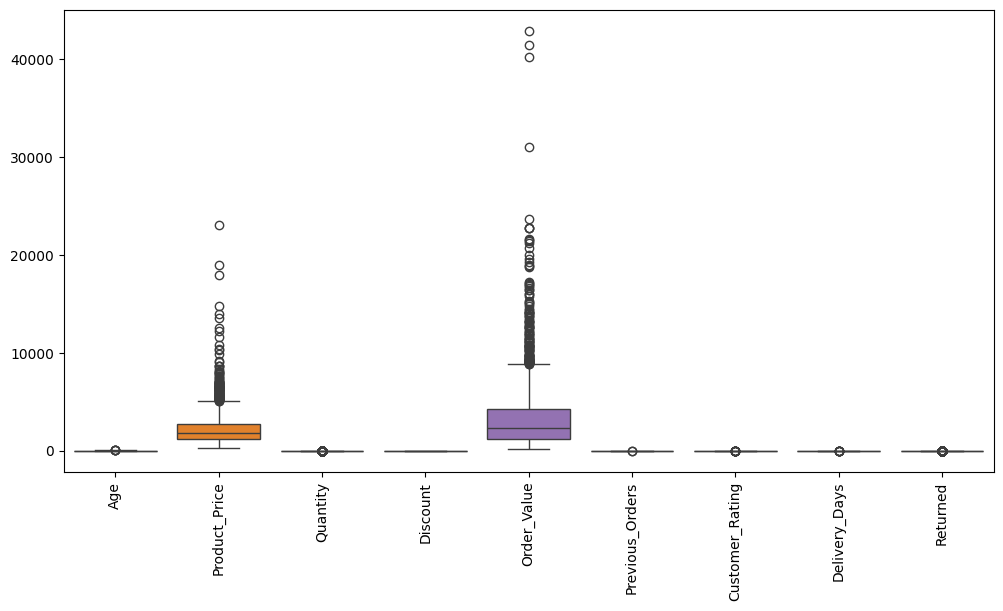

In [135]:
plt.figure(figsize=(12,6))
sns.boxplot(data=df.select_dtypes(include=['float64', 'int64']))
plt.xticks(rotation=90)
plt.show()

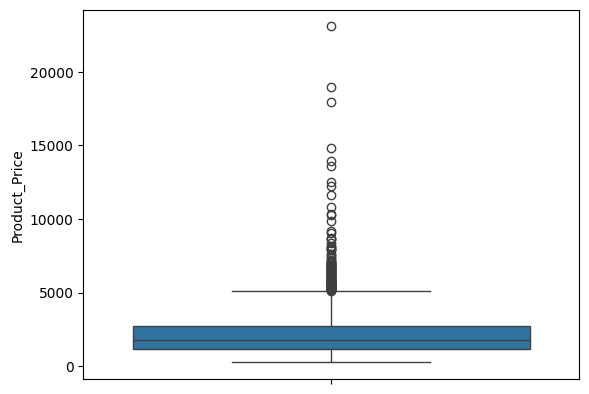

In [136]:
sns.boxplot(df['Product_Price'])
plt.show()


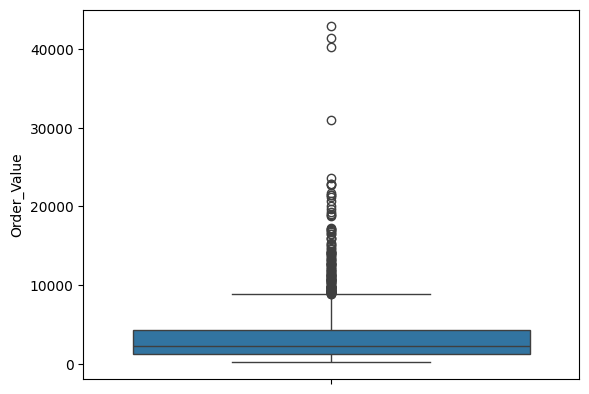

In [137]:
sns.boxplot(df['Order_Value'])
plt.show()


In [138]:
#outlier handling

q1 = df['Order_Value'].quantile(0.25)
q2 = df['Order_Value'].quantile(0.5)
q3 = df['Order_Value'].quantile(0.75)

In [139]:
print(f'Q1 ={q1}\nQ2 ={q2}\nQ3 ={q3}')
IQR = q3 -q1
up_lim = q3+(1.5*IQR)
low_lim = q1 -(1.5*IQR)
print(f'Iqr = {IQR} \n UPPER LIMIT = {up_lim} \n LOWER LIMIT = {low_lim}')

Q1 =1239.71
Q2 =2305.285
Q3 =4296.1050000000005
Iqr = 3056.3950000000004 
 UPPER LIMIT = 8880.697500000002 
 LOWER LIMIT = -3344.8825000000006


In [140]:
df.loc[df['Order_Value'] > up_lim, 'Order_Value'] = up_lim
df.loc[df['Order_Value'] < low_lim, 'Order_Value'] = low_lim

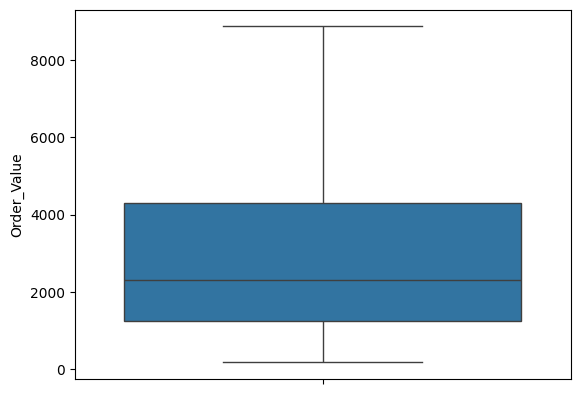

In [141]:
sns.boxplot(df['Order_Value'])
plt.show()

In [142]:

q1 = df['Product_Price'].quantile(0.25)
q2 = df['Product_Price'].quantile(0.5)
q3 = df['Product_Price'].quantile(0.75)

In [143]:
print(f'Q1 ={q1}\nQ2 ={q2}\nQ3 ={q3}')
IQR = q3 -q1
up_lim = q3+(1.5*IQR)
low_lim = q1 -(1.5*IQR)
print(f'Iqr = {IQR} \n UPPER LIMIT = {up_lim} \n LOWER LIMIT = {low_lim}')

Q1 =1169.48
Q2 =1800.4299999999998
Q3 =2741.895
Iqr = 1572.415 
 UPPER LIMIT = 5100.5175 
 LOWER LIMIT = -1189.1425


In [144]:
df.loc[df['Product_Price'] > up_lim, 'Product_Price'] = up_lim
df.loc[df['Product_Price'] < low_lim, 'Product_Price'] = low_lim

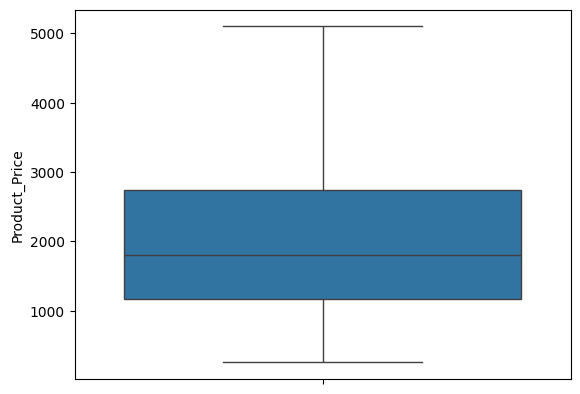

In [145]:
sns.boxplot(df['Product_Price'])
plt.show()

#Encoding

In [146]:

df.select_dtypes(include=object).columns



Index(['Gender', 'City', 'Product_Category', 'Payment_Method'], dtype='object')

In [147]:
df['Gender'].nunique()

3

In [148]:
df['Gender'].unique()

array(['Other', 'Male', 'Female'], dtype=object)

In [149]:
df['City'].nunique()

10

In [150]:
df['City'].unique()

array(['Thrissur', 'Delhi', 'Pune', 'Mumbai', 'Hyderabad',
       'Thiruvananthapuram', 'Bengaluru', 'Kozhikode', 'Kochi', 'Chennai'],
      dtype=object)

In [151]:
df['Product_Category'].nunique()

6

In [152]:
df['Product_Category'].unique()


array(['Electronics', 'Books', 'Beauty', 'Fashion', 'Sports',
       'Home & Kitchen'], dtype=object)

In [153]:
df['Payment_Method'].nunique()

5

In [154]:
df['Payment_Method'].unique()

array(['Debit Card', 'Net Banking', 'Cash on Delivery', 'Credit Card',
       'UPI'], dtype=object)

In [155]:
# apply onehot encoding

df= pd.get_dummies(df,dtype = 'int',drop_first= True)

In [156]:
df

,Age,Product_Price,Quantity,Discount,Order_Value,Previous_Orders,Customer_Rating,Delivery_Days,Returned,Gender_Male,...,City_Thrissur,Product_Category_Books,Product_Category_Electronics,Product_Category_Fashion,Product_Category_Home & Kitchen,Product_Category_Sports,Payment_Method_Credit Card,Payment_Method_Debit Card,Payment_Method_Net Banking,Payment_Method_UPI
0,39.0,1160.5800,2,24.9,1743.19,7.0,5.00000,1.0,0,0,...,1,0,1,0,0,0,0,1,0,0
1,33.0,1638.6100,1,3.0,1589.45,5.0,2.80000,7.0,0,1,...,0,1,0,0,0,0,0,0,1,0
2,40.0,1075.4200,5,20.1,4296.30,5.0,4.60000,2.0,0,1,...,0,1,0,0,0,0,0,0,0,0
3,49.0,1473.4600,2,7.3,2731.79,5.0,4.40000,6.0,0,1,...,0,0,0,0,0,0,1,0,0,0
4,32.0,525.6800,2,23.0,809.55,6.0,3.40000,3.0,0,0,...,0,0,0,1,0,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,45.0,1833.6100,2,20.2,2926.44,4.0,4.70000,2.0,0,0,...,0,1,0,0,0,0,0,0,1,0
1996,34.0,466.3600,1,1.2,460.76,7.0,3.80000,1.0,0,0,...,0,0,0,1,0,0,0,0,0,0
1997,25.0,1461.6900,1,5.3,1384.22,4.0,3.98901,7.0,0,0,...,0,0,0,0,0,1,1,0,0,0
1998,32.0,5100.5175,1,35.5,3378.65,4.0,3.60000,5.0,0,0,...,0,0,0,0,1,0,0,0,0,1


In [157]:
df.dtypes

,0
Age,float64
Product_Price,float64
Quantity,int64
Discount,float64
Order_Value,float64
Previous_Orders,float64
Customer_Rating,float64
Delivery_Days,float64
Returned,int64
Gender_Male,int64


In [158]:
df.head()

,Age,Product_Price,Quantity,Discount,Order_Value,Previous_Orders,Customer_Rating,Delivery_Days,Returned,Gender_Male,...,City_Thrissur,Product_Category_Books,Product_Category_Electronics,Product_Category_Fashion,Product_Category_Home & Kitchen,Product_Category_Sports,Payment_Method_Credit Card,Payment_Method_Debit Card,Payment_Method_Net Banking,Payment_Method_UPI
0,39.0,1160.58,2,24.9,1743.19,7.0,5.0,1.0,0,0,...,1,0,1,0,0,0,0,1,0,0
1,33.0,1638.61,1,3.0,1589.45,5.0,2.8,7.0,0,1,...,0,1,0,0,0,0,0,0,1,0
2,40.0,1075.42,5,20.1,4296.30,5.0,4.6,2.0,0,1,...,0,1,0,0,0,0,0,0,0,0
3,49.0,1473.46,2,7.3,2731.79,5.0,4.4,6.0,0,1,...,0,0,0,0,0,0,1,0,0,0
4,32.0,525.68,2,23.0,809.55,6.0,3.4,3.0,0,0,...,0,0,0,1,0,0,1,0,0,0


In [159]:
#separate feature and target column

In [160]:
y =df['Returned']
x =df.drop('Returned',axis=1)

In [173]:
x

,Age,Product_Price,Quantity,Discount,Order_Value,Previous_Orders,Customer_Rating,Delivery_Days,Gender_Male,Gender_Other,...,City_Thrissur,Product_Category_Books,Product_Category_Electronics,Product_Category_Fashion,Product_Category_Home & Kitchen,Product_Category_Sports,Payment_Method_Credit Card,Payment_Method_Debit Card,Payment_Method_Net Banking,Payment_Method_UPI
0,39.0,1160.5800,2,24.9,1743.19,7.0,5.00000,1.0,0,1,...,1,0,1,0,0,0,0,1,0,0
1,33.0,1638.6100,1,3.0,1589.45,5.0,2.80000,7.0,1,0,...,0,1,0,0,0,0,0,0,1,0
2,40.0,1075.4200,5,20.1,4296.30,5.0,4.60000,2.0,1,0,...,0,1,0,0,0,0,0,0,0,0
3,49.0,1473.4600,2,7.3,2731.79,5.0,4.40000,6.0,1,0,...,0,0,0,0,0,0,1,0,0,0
4,32.0,525.6800,2,23.0,809.55,6.0,3.40000,3.0,0,0,...,0,0,0,1,0,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,45.0,1833.6100,2,20.2,2926.44,4.0,4.70000,2.0,0,0,...,0,1,0,0,0,0,0,0,1,0
1996,34.0,466.3600,1,1.2,460.76,7.0,3.80000,1.0,0,0,...,0,0,0,1,0,0,0,0,0,0
1997,25.0,1461.6900,1,5.3,1384.22,4.0,3.98901,7.0,0,0,...,0,0,0,0,0,1,1,0,0,0
1998,32.0,5100.5175,1,35.5,3378.65,4.0,3.60000,5.0,0,0,...,0,0,0,0,1,0,0,0,0,1


In [174]:
y## creating copy of feature

x1= x.copy()

In [162]:
y =df['Returned'].reset_index(drop=True)
x =df.drop('Returned',axis=1).reset_index(drop=True)

In [175]:
x

,Age,Product_Price,Quantity,Discount,Order_Value,Previous_Orders,Customer_Rating,Delivery_Days,Gender_Male,Gender_Other,...,City_Thrissur,Product_Category_Books,Product_Category_Electronics,Product_Category_Fashion,Product_Category_Home & Kitchen,Product_Category_Sports,Payment_Method_Credit Card,Payment_Method_Debit Card,Payment_Method_Net Banking,Payment_Method_UPI
0,39.0,1160.5800,2,24.9,1743.19,7.0,5.00000,1.0,0,1,...,1,0,1,0,0,0,0,1,0,0
1,33.0,1638.6100,1,3.0,1589.45,5.0,2.80000,7.0,1,0,...,0,1,0,0,0,0,0,0,1,0
2,40.0,1075.4200,5,20.1,4296.30,5.0,4.60000,2.0,1,0,...,0,1,0,0,0,0,0,0,0,0
3,49.0,1473.4600,2,7.3,2731.79,5.0,4.40000,6.0,1,0,...,0,0,0,0,0,0,1,0,0,0
4,32.0,525.6800,2,23.0,809.55,6.0,3.40000,3.0,0,0,...,0,0,0,1,0,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,45.0,1833.6100,2,20.2,2926.44,4.0,4.70000,2.0,0,0,...,0,1,0,0,0,0,0,0,1,0
1996,34.0,466.3600,1,1.2,460.76,7.0,3.80000,1.0,0,0,...,0,0,0,1,0,0,0,0,0,0
1997,25.0,1461.6900,1,5.3,1384.22,4.0,3.98901,7.0,0,0,...,0,0,0,0,0,1,1,0,0,0
1998,32.0,5100.5175,1,35.5,3378.65,4.0,3.60000,5.0,0,0,...,0,0,0,0,1,0,0,0,0,1


In [176]:
y

,Returned
0,0
1,0
2,0
3,0
4,0
...,...
1995,0
1996,0
1997,0
1998,0


In [163]:
# train test split

In [164]:
# scaled x_train1 and x_test1
from sklearn.model_selection import train_test_split
x_train1, x_test1, y_train, y_test = train_test_split(x1, y, test_size=0.2, random_state=42,)

In [165]:
# non scaled x_train and x_test
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

#scaling

In [166]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
for i in x1.columns:
  x1[i] = scaler.fit_transform(x1[[i]])

#logistic regression

In [167]:
from sklearn.linear_model import LogisticRegression

In [168]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

lr_model_scaled = LogisticRegression(solver='liblinear', class_weight='balanced', max_iter=1000)
lr_model_scaled.fit(x_train1, y_train)

y_pred_lr_model_scaled = lr_model_scaled.predict(x_test1)
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr_model_scaled))
print('Accuracy is: ', accuracy_score(y_test, y_pred_lr_model_scaled))
print('Precision is: ', precision_score(y_test, y_pred_lr_model_scaled))
print('Recall is: ', recall_score(y_test, y_pred_lr_model_scaled))
print('F1 score is: ', f1_score(y_test, y_pred_lr_model_scaled))


Confusion Matrix:
[[221 143]
 [ 15  21]]
Accuracy is:  0.605
Precision is:  0.12804878048780488
Recall is:  0.5833333333333334
F1 score is:  0.21


In [169]:
#Decision tree

from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

dt_model_scaled = DecisionTreeClassifier(
    class_weight='balanced',
    random_state=42
)

dt_model_scaled.fit(x_train, y_train)

y_pred_dt_model_scaled = dt_model_scaled.predict(x_test)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt_model_scaled))

print('Accuracy is: ', accuracy_score(y_test, y_pred_dt_model_scaled))

print('Precision is: ', precision_score(y_test, y_pred_dt_model_scaled))

print('Recall is: ', recall_score(y_test, y_pred_dt_model_scaled))

print('f score is: ', f1_score(y_test, y_pred_dt_model_scaled))

Confusion Matrix:
[[326  38]
 [ 31   5]]
Accuracy is:  0.8275
Precision is:  0.11627906976744186
Recall is:  0.1388888888888889
f score is:  0.12658227848101267


In [170]:
#random forest

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    class_weight='balanced',
    max_depth=10,
    min_samples_split=5,
    random_state=42
)

rf_model.fit(x_train, y_train)

y_pred_rf = rf_model.predict(x_test)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_rf, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred_rf, zero_division=0))

Confusion Matrix:
[[361   3]
 [ 36   0]]
Accuracy: 0.9025
Precision: 0.0
Recall: 0.0
F1 Score: 0.0


In [171]:
#KNN

from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

knn_model_scaled = KNeighborsClassifier(n_neighbors=5)

knn_model_scaled.fit(x_train1, y_train)

y_pred_knn_model_scaled = knn_model_scaled.predict(x_test1)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_knn_model_scaled))

print('Accuracy is: ', accuracy_score(y_test, y_pred_knn_model_scaled))

print('Precision is: ', precision_score(y_test, y_pred_knn_model_scaled))

print('Recall is: ', recall_score(y_test, y_pred_knn_model_scaled))

print('F1 score is: ', f1_score(y_test, y_pred_knn_model_scaled))

Confusion Matrix:
[[356   8]
 [ 35   1]]
Accuracy is:  0.8925
Precision is:  0.1111111111111111
Recall is:  0.027777777777777776
F1 score is:  0.044444444444444446


In [172]:
#SVM

from sklearn.svm import SVC

from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

svm_model_scaled = SVC(
    class_weight='balanced',
    random_state=42
)

svm_model_scaled.fit(x_train1, y_train)

y_pred_svm_model_scaled = svm_model_scaled.predict(x_test1)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_svm_model_scaled))

print('Accuracy is: ', accuracy_score(y_test, y_pred_svm_model_scaled))

print('Precision is: ', precision_score(y_test, y_pred_svm_model_scaled))

print('Recall is: ', recall_score(y_test, y_pred_svm_model_scaled))

print('F1 score is: ', f1_score(y_test, y_pred_svm_model_scaled))

Confusion Matrix:
[[136 228]
 [ 10  26]]
Accuracy is:  0.405
Precision is:  0.10236220472440945
Recall is:  0.7222222222222222
F1 score is:  0.1793103448275862


“Among the evaluated classification models, Logistic Regression performed best overall based on the F1-score. Although SVM achieved the highest recall, Logistic Regression provided a better balance between precision and recall. Random Forest achieved the highest accuracy, but its recall and F1-score were zero because it failed to identify any positive cases. Therefore, Logistic Regression was selected as the best overall model.”